In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout


In [8]:
# Load MNIST Dataset
from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()


In [10]:
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Training Labels Shape: (60000,)
Testing Labels Shape: (10000,)


In [11]:
#Understanding the Dataset

# Display first 10 labels
print("First 10 Training Labels:")
print(y_train[:10])

# Display unique classes
print("\nUnique Classes:")
print(np.unique(y_train))

# Count total classes
print("\nTotal Number of Classes:")
print(len(np.unique(y_train)))

# Display total training and testing samples
print("\nTotal Training Samples:", len(x_train))
print("Total Testing Samples:", len(x_test))

First 10 Training Labels:
[5 0 4 1 9 2 1 3 1 4]

Unique Classes:
[0 1 2 3 4 5 6 7 8 9]

Total Number of Classes:
10

Total Training Samples: 60000
Total Testing Samples: 10000


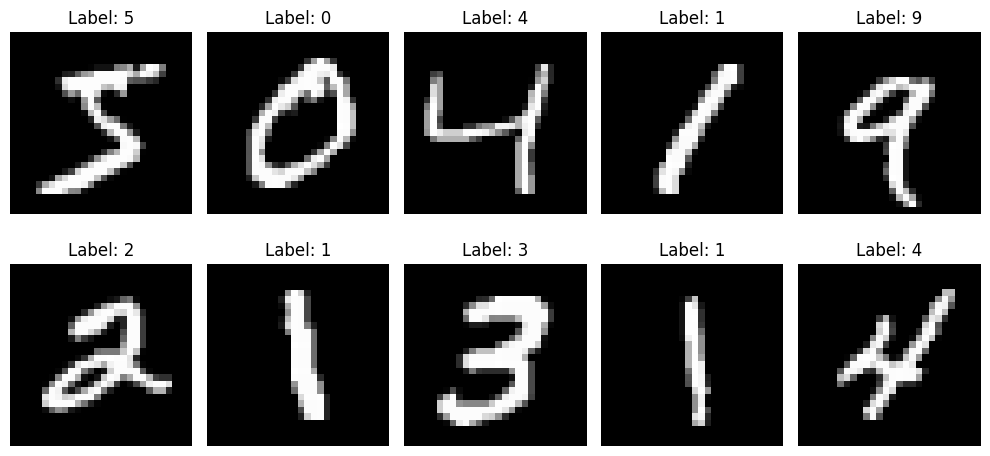

In [12]:
# Visualize Sample Images

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
# Data Preprocessing

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape images for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)


In [14]:
# Display new shapes
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

# Display minimum and maximum pixel values
print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

Training Data Shape: (60000, 28, 28, 1)
Testing Data Shape: (10000, 28, 28, 1)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [16]:
# Build CNN Model

model = Sequential()

# First Convolutional Layer
model.add(Conv2D(32, (3, 3), activation='relu',
                 input_shape=(28, 28, 1)))

# First Max Pooling Layer
model.add(MaxPooling2D((2, 2)))

# Second Convolutional Layer
model.add(Conv2D(64, (3, 3), activation='relu'))

# Second Max Pooling Layer
model.add(MaxPooling2D((2, 2)))

# Flatten Layer
model.add(Flatten())

# Fully Connected Layer
model.add(Dense(64, activation='relu'))

# Dropout Layer
model.add(Dropout(0.3))

# Output Layer
model.add(Dense(10, activation='softmax'))

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [17]:
# Compile CNN Model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [18]:
# Display CNN Model Summary

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Train CNN Model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("CNN Model Training Completed!")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.9218 - loss: 0.2591 - val_accuracy: 0.9833 - val_loss: 0.0582
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.9744 - loss: 0.0879 - val_accuracy: 0.9872 - val_loss: 0.0433
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.9809 - loss: 0.0645 - val_accuracy: 0.9890 - val_loss: 0.0371
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9839 - loss: 0.0519 - val_accuracy: 0.9897 - val_loss: 0.0352
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.9866 - loss: 0.0427 - val_accuracy: 0.9908 - val_loss: 0.0369
CNN Model Training Completed!


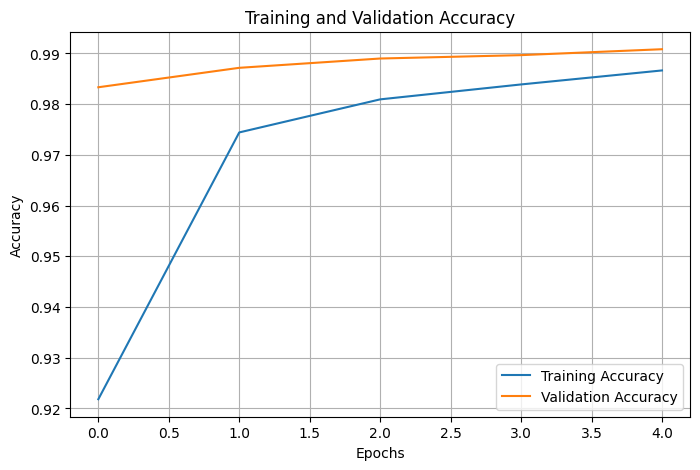

In [20]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

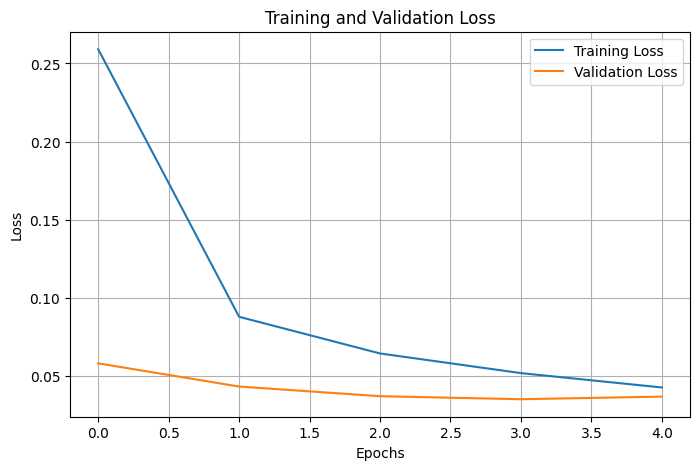

In [21]:
# Plot Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [22]:
# Evaluate CNN Model

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9892 - loss: 0.0352
Test Loss: 0.03523871675133705
Test Accuracy: 98.91999959945679 %


In [23]:
# Predict Test Images

y_pred = model.predict(x_test)

predicted_labels = np.argmax(y_pred, axis=1)

print("Actual Labels:   ", y_test[:10])
print("Predicted Labels:", predicted_labels[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Actual Labels:    [7 2 1 0 4 1 4 9 5 9]
Predicted Labels: [7 2 1 0 4 1 4 9 5 9]


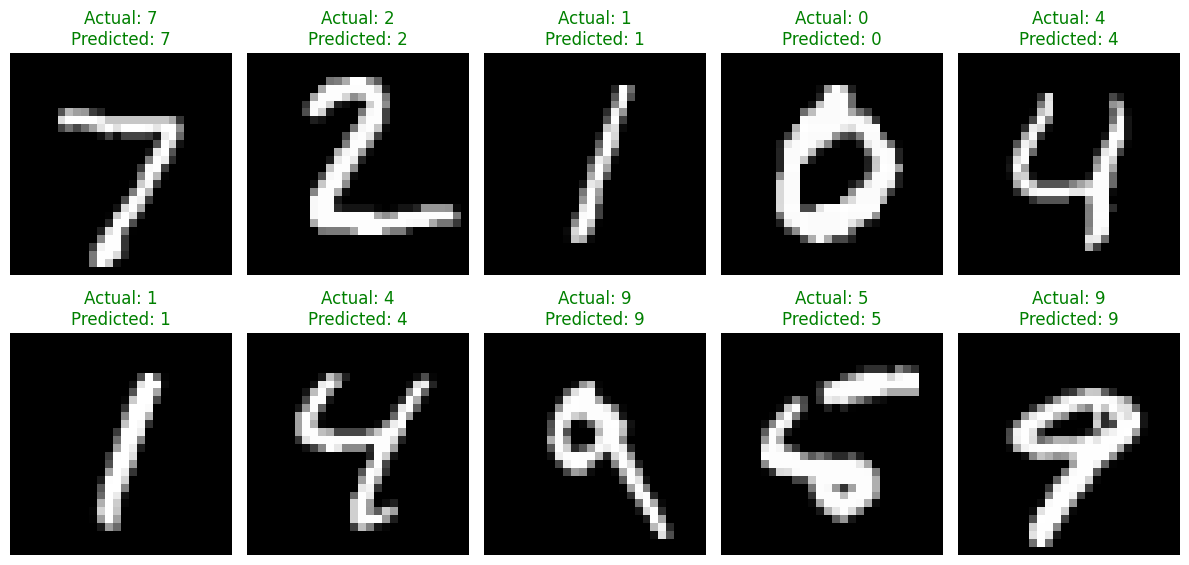

In [24]:
# Visualize Actual vs Predicted Labels

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    actual = y_test[i]
    predicted = predicted_labels[i]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color='green' if actual == predicted else 'red'
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [25]:
# Correct and Incorrect Predictions

correct = np.sum(y_test == predicted_labels)
incorrect = np.sum(y_test != predicted_labels)

print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)

print("Total Predictions:", len(y_test))

Correct Predictions: 9892
Incorrect Predictions: 108
Total Predictions: 10000


In [26]:
# Install Streamlit

!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 105.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 121.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [27]:
# Import Streamlit

import streamlit as st

print("Streamlit imported successfully!")

Streamlit imported successfully!
